In [ ]:
#!python -m pip install numpy pandas matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df = pd.read_csv(r'C:\Users\DELL\Downloads\NTI-Machine-Learning_streamlit\NTI-Machine-Learning\Task01_Stroke_Dataset\dataset\stroke.csv')

In [ ]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
df.shape

(5110, 12)

In [ ]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [ ]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df=df.drop(columns=['id']).copy()

In [ ]:
df = df[df['gender'] != 'Other'].copy()

In [ ]:
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

In [ ]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

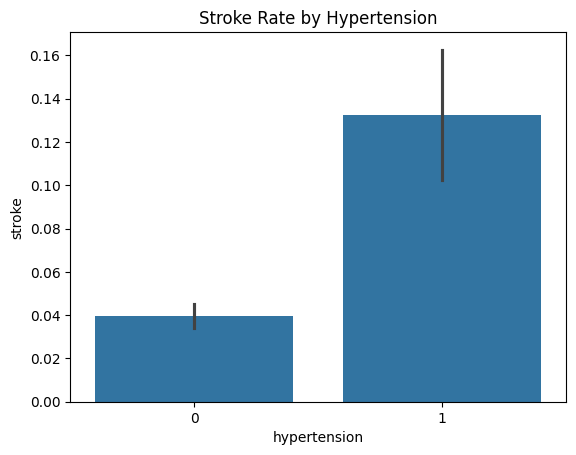

In [ ]:
sns.barplot(data=df, x='hypertension', y='stroke')
plt.title("Stroke Rate by Hypertension")
plt.show()

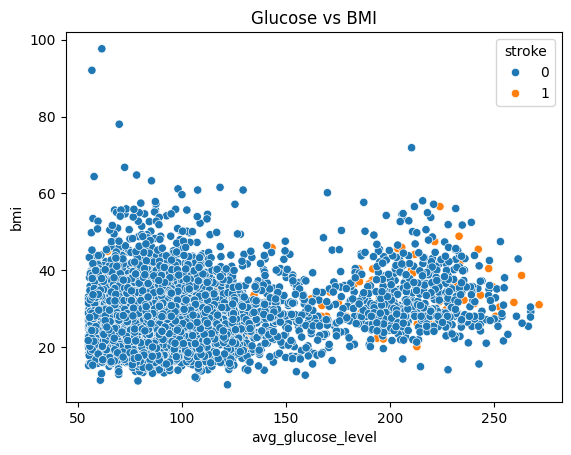

In [ ]:
sns.scatterplot(data=df, x='avg_glucose_level', y='bmi', hue='stroke')
plt.title("Glucose vs BMI")
plt.show()

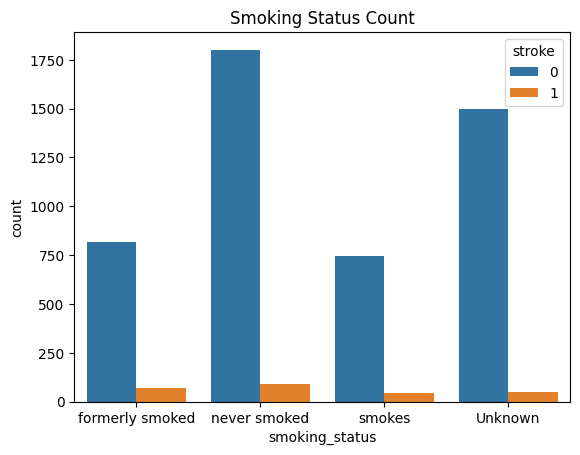

In [ ]:
sns.countplot(data=df, x='smoking_status', hue='stroke')
plt.title("Smoking Status Count")
plt.show()

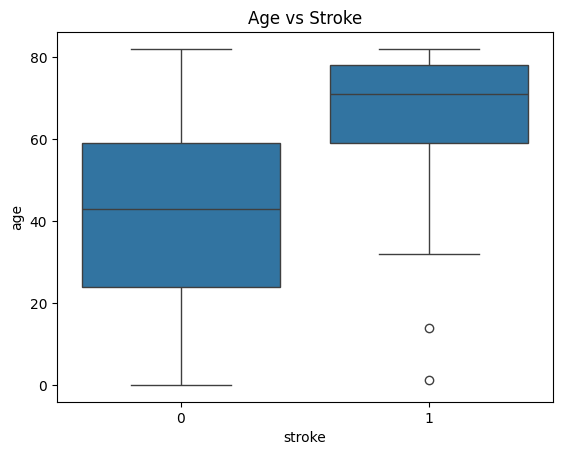

In [ ]:
sns.boxplot(data=df, x='stroke', y='age')
plt.title("Age vs Stroke")
plt.show()

In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


In [ ]:
model.score(X_train_scaled, y_train)


0.7397260273972602

In [ ]:
model.score(X_test_scaled, y_test)

0.7455968688845401

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
    AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Lasso": LogisticRegression(penalty='l1', solver='liblinear'),
    "Ridge": RidgeClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVC(kernel='rbf', C=1),
    "Decision Tree": DecisionTreeClassifier(criterion='gini', max_depth=10),
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [ ]:
clf_results = []
clf_preds = {}

for name, model in clf_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    clf_preds[name] = y_pred

    clf_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

clf_results_df = pd.DataFrame(clf_results).sort_values(by='F1 Score', ascending=False)
clf_results_df.reset_index(drop=True, inplace=True)
clf_results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.949119,0.400000,0.08,0.133333
1,HistGradientBoosting,0.945205,0.250000,0.06,0.096774
2,LightGBM,0.944227,0.230769,0.06,0.095238
3,Decision Tree,0.929550,0.107143,0.06,0.076923
4,KNN,0.949119,0.333333,0.04,0.071429
5,Lasso,0.952055,1.000000,0.02,0.039216
6,Logistic Regression,0.952055,1.000000,0.02,0.039216
7,Random Forest,0.950098,0.333333,0.02,0.037736
8,Bagging,0.947162,0.166667,0.02,0.035714
9,ExtraTrees,0.942270,0.090909,0.02,0.032787


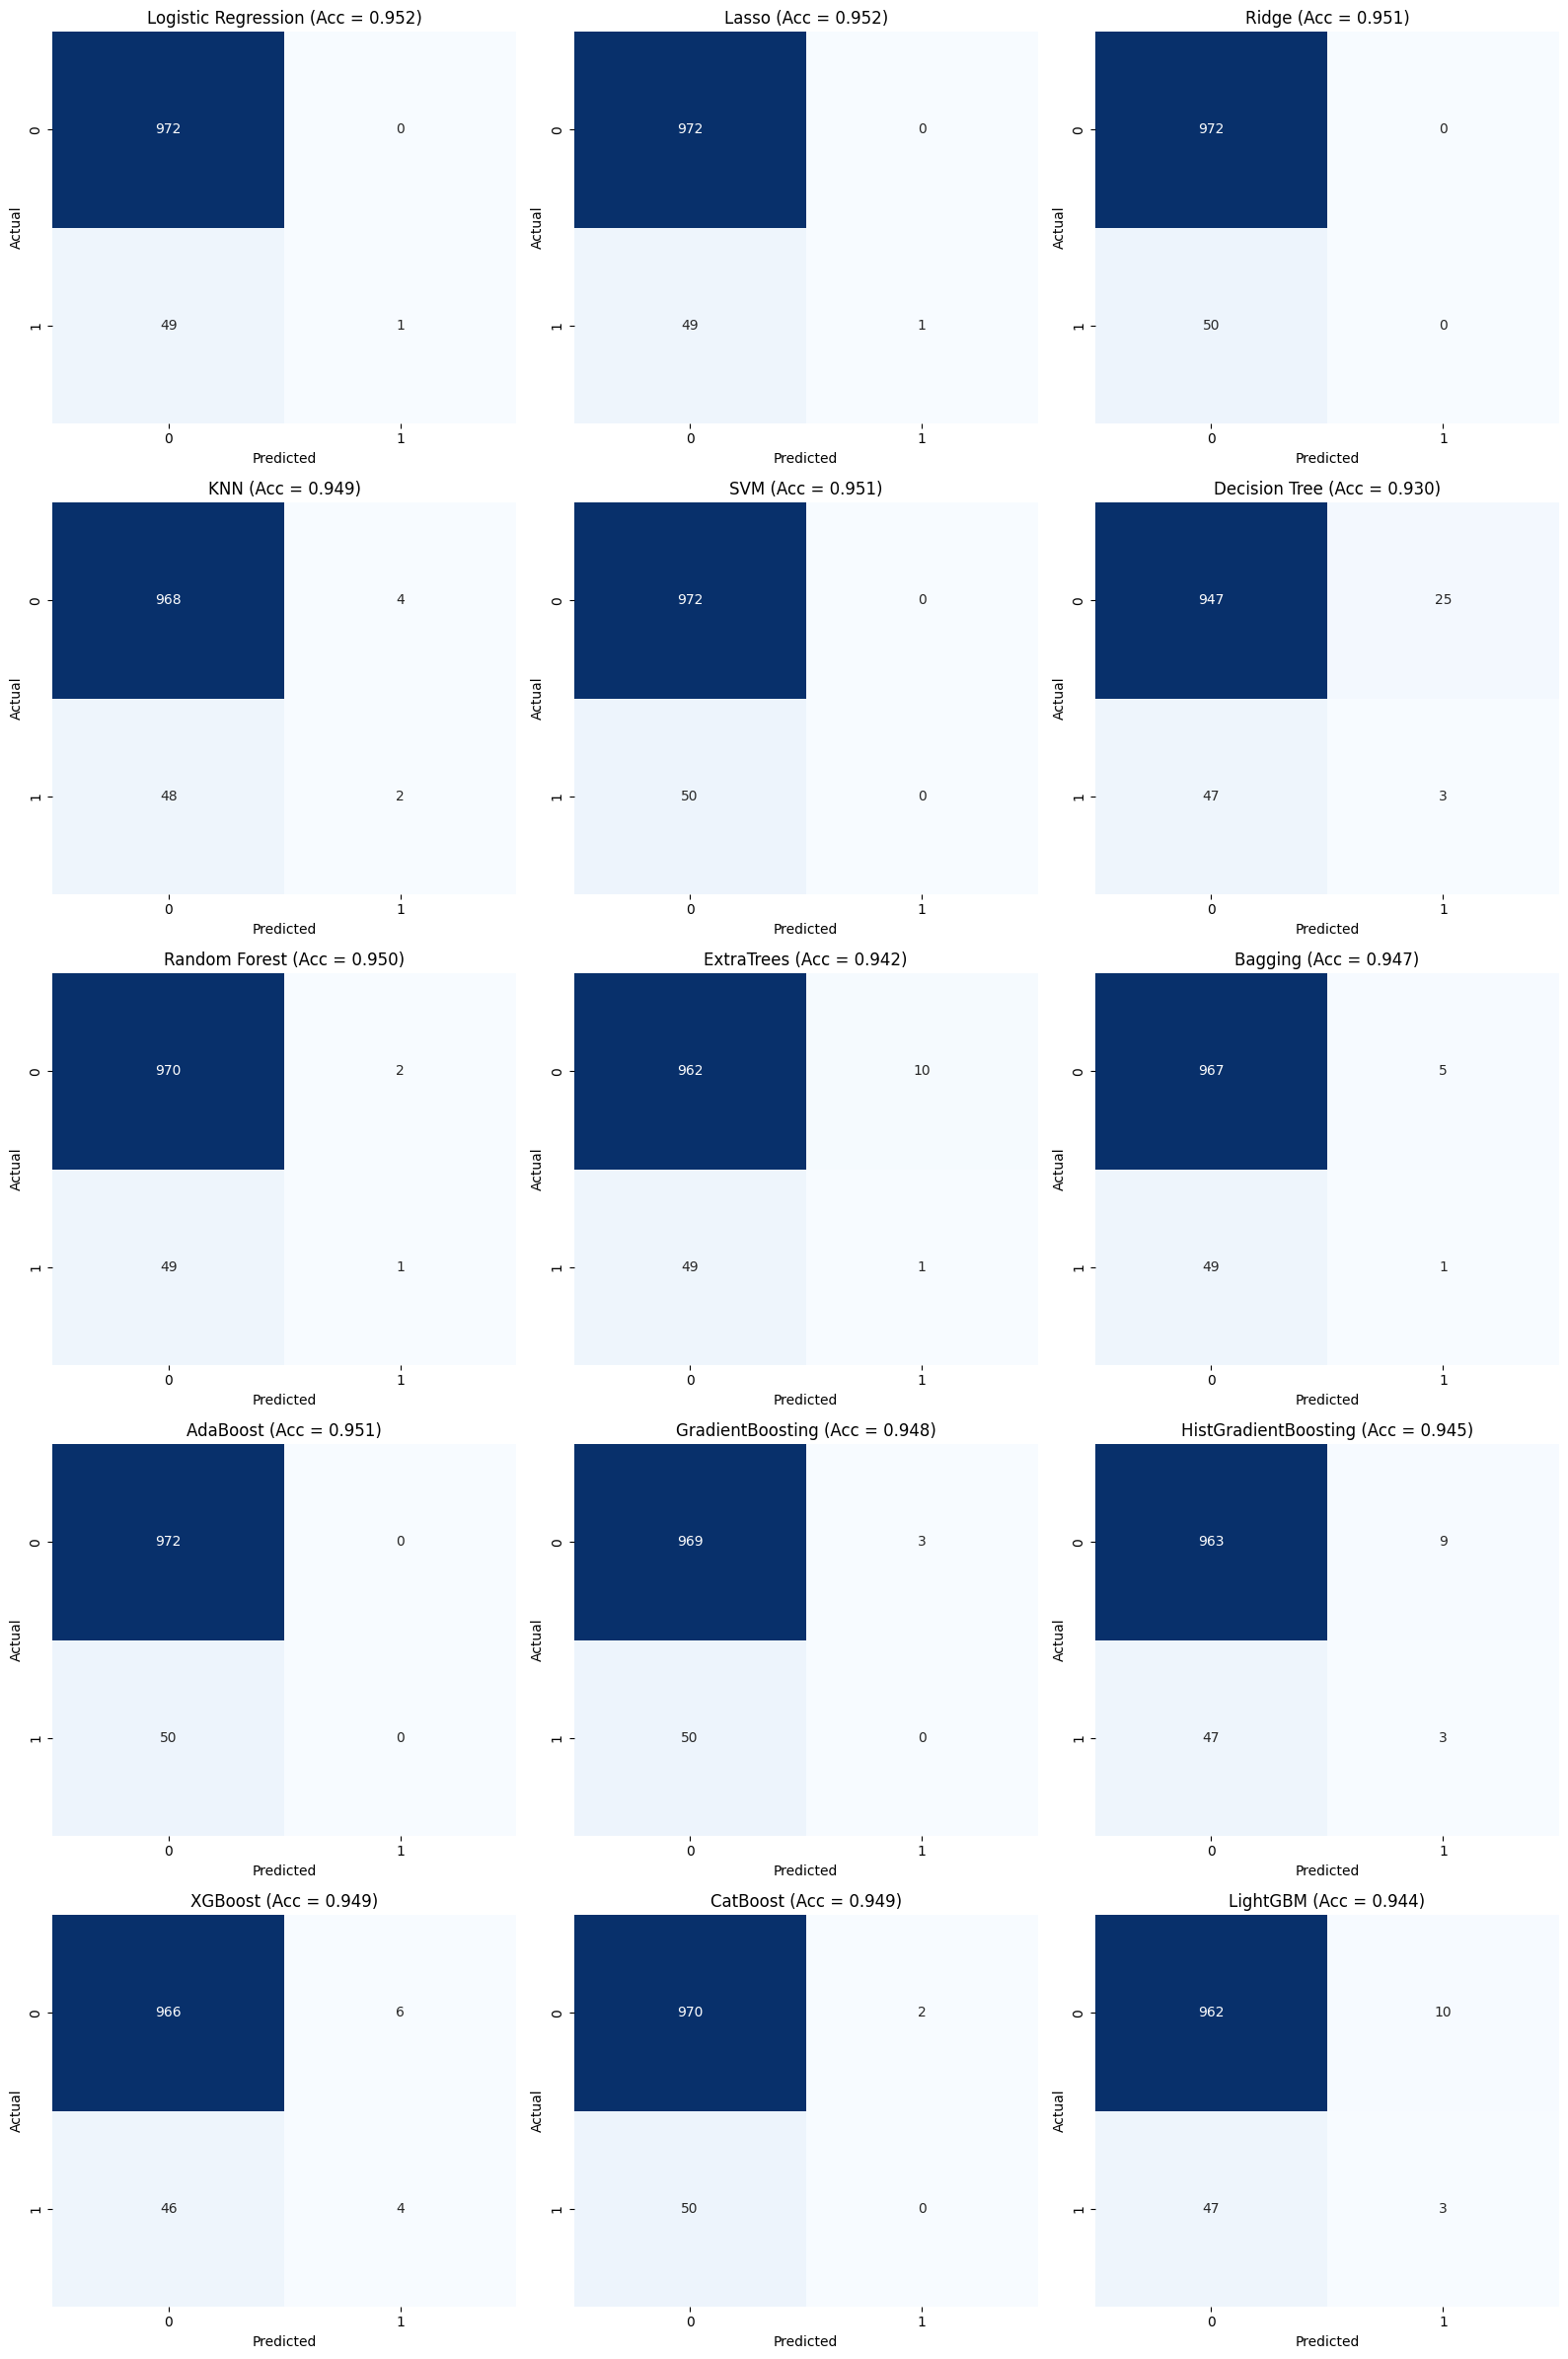

In [ ]:
fig, axes = plt.subplots(5, 3, figsize=(16, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(clf_preds.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i])
    axes[i].set_title(f"{name} (Acc = {accuracy_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Model comparison (F1)

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=clf_results_df, x='F1 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('F1 Score Comparison')
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in clf_models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='f1', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV F1': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV F1', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Lasso": {"C": [0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [0.1, 1, 10]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(clf_models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

base_model = clone(clf_models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p, zero_division=0),
                 'Recall': recall_score(y_test, p, zero_division=0),
                 'F1': f1_score(y_test, p, zero_division=0)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

y_pred = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_estimator(best_model, X_test_scaled, y_test, ax=axes[2])
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
from sklearn.metrics import confusion_matrix

if hasattr(best_model, 'predict_proba'):
    scores = best_model.predict_proba(X_test_scaled)[:, 1]
else:
    scores = best_model.decision_function(X_test_scaled)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- Accuracy = {acc:.3f}: {acc*100:.1f}% of all predictions are correct.")
print(f"- Precision = {prec:.3f}: when the model predicts the positive class, it is right {prec*100:.1f}% of the time ({fp} false alarms).")
print(f"- Recall = {rec:.3f}: the model finds {rec*100:.1f}% of the real positive cases and misses {fn}.")
print(f"- F1 = {f1:.3f}: the balance between precision and recall.")
print(f"- ROC-AUC = {roc_auc_score(y_test, scores):.3f}: the chance that a random positive case is ranked above a random negative one.")
print(f"- Average Precision (PR curve) = {average_precision_score(y_test, scores):.3f}: more reliable than accuracy when the classes are imbalanced.")
if rec < prec:
    print("- Recall is lower than precision: the model is careful but misses some positive cases.")
else:
    print("- Precision is lower than recall: the model catches most positive cases but raises some false alarms.")

## Save the model for the Streamlit app
This creates `model.joblib`. Put it next to `app.py`.

In [ ]:
cat_cols = df.drop(columns=['stroke']).select_dtypes(exclude='number').columns.tolist()
import joblib

# original columns (before get_dummies) -> used to build the form in the app
raw = df.drop(columns=['stroke'])
inputs = {}
for col in raw.columns:
    if col in cat_cols or raw[col].nunique() <= 2:
        inputs[col] = ('choice', sorted(raw[col].unique().tolist()))
    elif pd.api.types.is_integer_dtype(raw[col]):
        inputs[col] = ('number', int(raw[col].min()), int(raw[col].max()), int(raw[col].median()))
    else:
        inputs[col] = ('number', float(raw[col].min()), float(raw[col].max()), float(raw[col].median()))

joblib.dump({'model': best_model,
             'scaler': scaler,
             'inputs': inputs,
             'cat_cols': cat_cols,
             'dummy_columns': list(X_train.columns)}, 'model.joblib', compress=3)